# 02 — Fire hotspots by source region and compass sector (Medellín)

Mirrors Bogotá's notebook 04 exactly, just re-centered on Medellín. Reuses the same
`load_hotspots_daily_by_region` (fixed real-world point sources: Caquetá, Magdalena
Valley, Nevados -- all from Casallas et al. 2024's exact coordinates, city-independent)
and `load_hotspots_daily_by_sector` (already parameterized by `lat`/`lon`, no code
changes needed) from `common/external_data.py`. Medellín sits much closer to the
Magdalena Valley and Nevados sources than Bogotá does, so these may matter more here.

**Coverage gap** (same as Bogotá): the hotspot product only covers through 2023-12-31.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import pandas as pd
import matplotlib.pyplot as plt

from common.external_data import (
    load_hotspots_daily_by_region, load_hotspots_daily_by_sector,
    FIRE_SOURCE_REGIONS, MEDELLIN_LAT, MEDELLIN_LON,
)

OUT_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "medellin"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "medellin" / "figures"
# 2026-10-20: the old 2013-2023 product was spatially wrong in most years (daily totals right, locations wrong); this is the FIRMS
# regeneration (VIIRS S-NPP 375 m, same 0.75 deg grid, 2013 -> 2026-10-19). Master datasets were rebuilt from it with
# Scripts/colombia/rebuild_fire_columns.py (validated to reproduce the old columns exactly from the old grid).
HOTSPOTS_NC = PROJECT_ROOT / "Data" / "external" / "firms" / "Hotspots_count_2013-2026-10-19_South_America_FIRMS.nc"

print(f"Medellin at ({MEDELLIN_LAT}, {MEDELLIN_LON})")
for name, cfg in FIRE_SOURCE_REGIONS.items():
    print(f"{name:20s} lat={cfg['lat']:6.2f} lon={cfg['lon']:7.2f} radius={cfg['radius_km']:.0f} km")


Medellin at (6.244, -75.581)
caqueta              lat=  1.03 lon= -73.90 radius=220 km
magdalena_valley     lat=  7.06 lon= -73.85 radius=180 km
nevados              lat=  4.60 lon= -75.36 radius=100 km


In [2]:
hotspots_regions = load_hotspots_daily_by_region(HOTSPOTS_NC, FIRE_SOURCE_REGIONS)
hotspots_sectors = load_hotspots_daily_by_sector(HOTSPOTS_NC, lat=MEDELLIN_LAT, lon=MEDELLIN_LON)
hotspots = hotspots_regions.merge(hotspots_sectors, on='date', how='outer')
print(hotspots.shape)
print(hotspots['date'].min(), hotspots['date'].max())
hotspots.head()


(4017, 12)
2013-01-01 00:00:00 2023-12-31 00:00:00


,date,hotspots_caqueta,hotspots_magdalena_valley,hotspots_nevados,hotspots_sector_N,hotspots_sector_NE,hotspots_sector_E,hotspots_sector_SE,hotspots_sector_S,hotspots_sector_SW,hotspots_sector_W,hotspots_sector_NW
0,2013-01-01,0.0,30.0,10.0,8.0,126.0,717.0,35.0,10.0,8.0,0.0,0.0
1,2013-01-02,0.0,55.0,5.0,15.0,130.0,950.0,80.0,13.0,2.0,3.0,2.0
2,2013-01-03,2.0,48.0,16.0,68.0,211.0,1231.0,76.0,26.0,53.0,6.0,3.0
3,2013-01-04,4.0,46.0,11.0,84.0,355.0,1267.0,86.0,31.0,34.0,1.0,1.0
4,2013-01-05,20.0,42.0,7.0,55.0,308.0,1608.0,156.0,26.0,3.0,1.0,2.0


## Monthly climatology sanity check

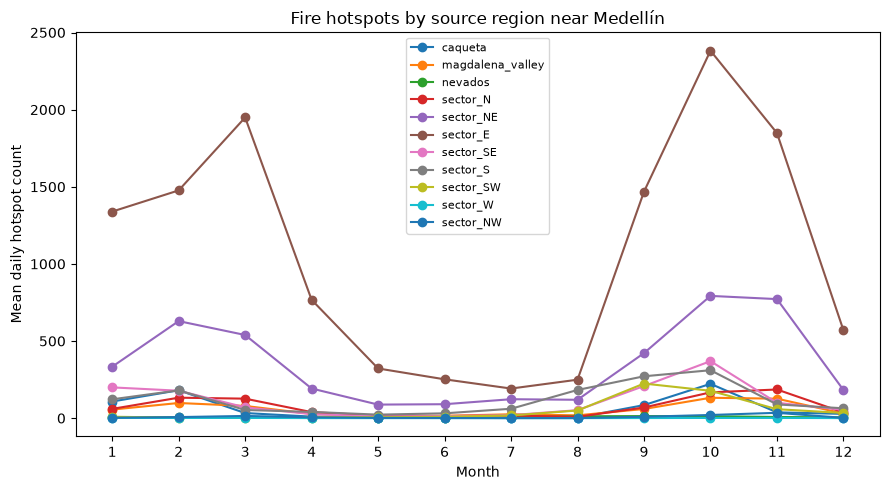

In [3]:
region_cols = [c for c in hotspots.columns if c.startswith('hotspots_')]
monthly = hotspots.set_index('date')[region_cols].groupby(
    hotspots.set_index('date').index.month
).mean()

fig, ax = plt.subplots(figsize=(9, 5))
for col in region_cols:
    ax.plot(monthly.index, monthly[col], marker='o', label=col.replace('hotspots_', ''))
ax.set_xticks(range(1, 13))
ax.set_xlabel('Month'); ax.set_ylabel('Mean daily hotspot count')
ax.set_title('Fire hotspots by source region near Medellín')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / 'hotspots_by_region_monthly.png', dpi=150)
plt.show()


## Save

In [4]:
out_path = OUT_DIR / "medellin_hotspots_daily.parquet"
hotspots.to_parquet(out_path, index=False)
print("Saved:", out_path, hotspots.shape)


Saved: /path/to/project/Data/processed/colombia/medellin/medellin_hotspots_daily.parquet (4017, 12)
